# FIT4013 – ĐỀ TÀI 15: DỰ ĐOÁN ĐIỂM CHẤT LƯỢNG RƯỢU VANG

**Nhóm 4 – CNTT 18-09**  
**Thành viên:** Phạm Danh Thái · Ngô Văn Hiếu · Phạm Anh Quân  
**Nguồn dữ liệu:** UCI Wine Quality (Cortez và cộng sự, 2009)

**Câu hỏi nghiên cứu:** Dựa trên các chỉ tiêu hóa lý, mô hình hồi quy nào dự đoán điểm chất lượng rượu vang tốt hơn mô hình dự đoán trung bình? Việc thay đổi tiền xử lý ảnh hưởng thế nào đến kết quả?


## Mission 1 – Bài toán và cơ sở lý thuyết

**Bài toán:** dự đoán biến số `quality` từ các thuộc tính hóa lý; đây là **hồi quy** vì đầu ra được xem như một giá trị số. Dù điểm gốc là số nguyên, mô hình hồi quy có thể dự đoán số thực.

**Mô hình cơ sở (DummyRegressor):** luôn dự đoán trung bình `quality` của tập huấn luyện, là mốc để biết thuật toán có học được tín hiệu hay không.

**KNN hồi quy:** với mẫu $x$, tìm $k$ điểm gần nhất theo khoảng cách Euclidean:

$$d(x,z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$

Dự đoán là trung bình nhãn của hàng xóm (hoặc trung bình có trọng số theo nghịch đảo khoảng cách). **K nhỏ** có thể nhạy với nhiễu; **K lớn** làm dự đoán mượt hơn nhưng có thể mất chi tiết.

**Cây quyết định hồi quy:** chia không gian đặc trưng theo các điều kiện để giảm sai số trong từng vùng; độ sâu quá lớn có thể làm mô hình quá khớp.

**Giới hạn:** dữ liệu có tính quan sát, không đủ để kết luận quan hệ nhân quả; điểm cảm quan có yếu tố chủ quan.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import urllib.request
import json

plt.rcParams['font.family'] = ['Noto Sans', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
DATA_DIR = Path('data')
OUT_DIR = Path('results')
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
print('Đã chuẩn bị môi trường. Thư mục dữ liệu:', DATA_DIR.resolve())

Đã chuẩn bị môi trường. Thư mục dữ liệu: E:\DeTai15_BanNangCap_BaoVe\DeTai15_BanBaoVe_Nhom4\data


## Mission 2 – Khám phá dữ liệu (EDA)

Bộ UCI Wine Quality gồm rượu đỏ và trắng. Các tệp dùng dấu `;` làm dấu phân cách. Nhóm ghép hai bảng và bổ sung `wine_type` (1 = đỏ, 0 = trắng) để mô hình nhận biết loại rượu.

**Cần kiểm tra:** kích thước, tên đặc trưng, giá trị thiếu, thống kê và sự mất cân đối giữa các mức điểm. Phân phối nhãn không đồng đều có thể khiến mô hình dễ dự đoán các mức điểm phổ biến hơn.

In [2]:
BASE_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/'
frames = []
for filename, wine_type in [('winequality-red.csv', 1), ('winequality-white.csv', 0)]:
    path = DATA_DIR / filename
    if not path.exists():
        print('Đang tải dữ liệu:', filename)
        urllib.request.urlretrieve(BASE_URL + filename, path)
    frame = pd.read_csv(path, sep=';')
    frame['wine_type'] = wine_type
    frames.append(frame)
df = pd.concat(frames, ignore_index=True)
print('Số mẫu:', len(df), '| Số cột:', df.shape[1])
print('Tổng giá trị thiếu:', int(df.isna().sum().sum()))
print('5 dòng dữ liệu đầu tiên (tên đặc trưng giữ nguyên theo UCI):')
display(df.head())
print('Bảng thống kê mô tả:')
display(df.describe().rename(index={'count':'Số lượng','mean':'Trung bình','std':'Độ lệch chuẩn','min':'Nhỏ nhất','25%':'Phân vị 25%','50%':'Trung vị','75%':'Phân vị 75%','max':'Lớn nhất'}).round(3))

Đang tải dữ liệu: winequality-red.csv
Đang tải dữ liệu: winequality-white.csv
Số mẫu: 6497 | Số cột: 13
Tổng giá trị thiếu: 0
5 dòng dữ liệu đầu tiên (tên đặc trưng giữ nguyên theo UCI):


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Bảng thống kê mô tả:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
Số lượng,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
Trung bình,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818,0.246
Độ lệch chuẩn,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873,0.431
Nhỏ nhất,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000,0.000
Phân vị 25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000,0.000
Trung vị,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000,0.000
Phân vị 75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000,0.000
Lớn nhất,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000,1.000


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

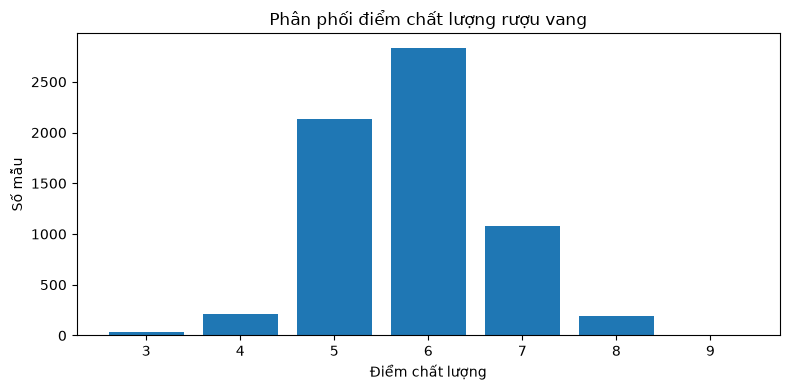

,Số mẫu
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


In [3]:
counts = df['quality'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.index.astype(str), counts.values)
ax.set(title='Phân phối điểm chất lượng rượu vang', xlabel='Điểm chất lượng', ylabel='Số mẫu')
plt.tight_layout()
plt.savefig(OUT_DIR / 'phan_phoi_chat_luong_ruou.png', dpi=150)
plt.show()
display(counts.rename('Số mẫu').to_frame())

In [4]:
print(f"NHẬN XÉT EDA: Tập dữ liệu có {len(df):,} mẫu, {X.shape[1] if 'X' in globals() else df.shape[1]-1} đặc trưng đầu vào.")
print(f"Điểm xuất hiện nhiều nhất: {int(counts.idxmax())} ({int(counts.max())} mẫu, {counts.max()/len(df)*100:.1f}%).")
print(f"Điểm xuất hiện ít nhất: {int(counts.idxmin())} ({int(counts.min())} mẫu, {counts.min()/len(df)*100:.2f}%).")
print('Nhận xét: Các mức điểm có tần suất khác nhau; cần xem sai số theo từng mức điểm, không chỉ MAE chung.')

NHẬN XÉT EDA: Tập dữ liệu có 6,497 mẫu, 12 đặc trưng đầu vào.
Điểm xuất hiện nhiều nhất: 6 (2836 mẫu, 43.7%).
Điểm xuất hiện ít nhất: 9 (5 mẫu, 0.08%).
Nhận xét: Các mức điểm có tần suất khác nhau; cần xem sai số theo từng mức điểm, không chỉ MAE chung.


## Mission 3 – Chia dữ liệu và tránh rò rỉ thông tin

Chia ngẫu nhiên **80% huấn luyện / 20% kiểm tra** với `random_state=42`. Không dùng `quality` làm đầu vào. Bộ chuẩn hóa, điền khuyết và chọn đặc trưng phải **fit trên train**; đặt chúng bên trong `Pipeline` để từng fold kiểm định chéo không sử dụng thống kê của fold đánh giá.

**Lưu ý:** bộ dữ liệu gốc thường không có giá trị thiếu, nhưng vẫn kiểm tra thực tế trước khi diễn giải tác dụng của bước điền khuyết.

In [5]:
X = df.drop(columns=['quality'])
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Số mẫu huấn luyện:', len(X_train))
print('Số mẫu kiểm tra:', len(X_test))
print('Số đặc trưng:', X.shape[1])

Số mẫu huấn luyện: 5197
Số mẫu kiểm tra: 1300
Số đặc trưng: 12


In [6]:
print('NHẬN XÉT CHIA DỮ LIỆU:')
print(f'Train = {len(X_train)} mẫu ({len(X_train)/len(df)*100:.1f}%), test = {len(X_test)} mẫu ({len(X_test)/len(df)*100:.1f}%).')
print('Các phép biến đổi được đặt trong Pipeline; kiểm định chéo chỉ học thống kê từ các fold huấn luyện.')

NHẬN XÉT CHIA DỮ LIỆU:
Train = 5197 mẫu (80.0%), test = 1300 mẫu (20.0%).
Các phép biến đổi được đặt trong Pipeline; kiểm định chéo chỉ học thống kê từ các fold huấn luyện.


## Mission 4 – Mô hình và phương án tiền xử lý

- **Phương án A:** điền thiếu bằng trung vị → `StandardScaler` (trừ trung bình, chia độ lệch chuẩn) → mô hình.
- **Phương án B:** điền thiếu bằng trung vị → `RobustScaler` (trừ trung vị, chia IQR) → `SelectKBest(f_regression, k=8)` → mô hình.

**Vì sao thử hai phương án?** KNN dựa trên khoảng cách nên nhạy với thang đo; RobustScaler có thể ít bị ảnh hưởng bởi giá trị ngoại lệ hơn StandardScaler. Việc chọn 8 đặc trưng có thể giảm nhiễu nhưng cũng có nguy cơ loại bỏ thông tin hữu ích. Chỉ kết quả kiểm định chéo mới cho biết phương án nào phù hợp với bộ dữ liệu này.

**Các siêu tham số:** KNN thử `k = 3, 5, 9, 15` và trọng số `uniform/distance`; cây quyết định thử độ sâu và số mẫu tối thiểu ở lá.

In [7]:
def make_pipeline(model, variant):
    steps = [('dien_thieu', SimpleImputer(strategy='median'))]
    if variant == 'A':
        steps.append(('chuan_hoa', StandardScaler()))
    else:
        steps.extend([('chuan_hoa', RobustScaler()),
                      ('chon_dac_trung', SelectKBest(score_func=f_regression, k=8))])
    steps.append(('model', model))
    return Pipeline(steps)

configs = [
    ('Mô hình cơ sở', 'A', DummyRegressor(strategy='mean'), {}),
    ('KNN', 'A', KNeighborsRegressor(), {'model__n_neighbors':[3,5,9,15], 'model__weights':['uniform','distance']}),
    ('KNN', 'B', KNeighborsRegressor(), {'model__n_neighbors':[3,5,9,15], 'model__weights':['uniform','distance']}),
    ('Cây quyết định', 'A', DecisionTreeRegressor(random_state=42), {'model__max_depth':[4,8,12,None], 'model__min_samples_leaf':[1,5,10]}),
    ('Cây quyết định', 'B', DecisionTreeRegressor(random_state=42), {'model__max_depth':[4,8,12,None], 'model__min_samples_leaf':[1,5,10]})
]
print('Số cấu hình mô hình:', len(configs))

Số cấu hình mô hình: 5


## Mission 5 – Huấn luyện và kiểm định chéo

**5-fold CV:** chia tập train thành 5 phần; lần lượt dùng 4 phần học và 1 phần đánh giá. `GridSearchCV` chọn siêu tham số có **MAE trung bình qua 5 fold nhỏ nhất**. Dùng `scoring='neg_mean_absolute_error'` vì scikit-learn tối đa hóa điểm số; dấu âm được đổi lại để báo cáo MAE dương.

**Nguyên tắc đánh giá:** chỉ chọn mô hình bằng **CV MAE** trên train. Kết quả test chỉ dùng để báo cáo, không dùng để chọn mô hình tốt nhất. Vì bảng trình bày test cho tất cả mô hình, việc xem test để chỉnh tiếp sẽ làm mất tính độc lập của tập kiểm tra.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows, predictions, fitted = [], {}, {}
for name, variant, model, params in configs:
    key = f'{name}_{variant}'
    print('Đang huấn luyện:', key)
    search = GridSearchCV(make_pipeline(model, variant), params, cv=cv,
                          scoring='neg_mean_absolute_error', n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    pred = search.predict(X_test)
    predictions[key] = pred
    fitted[key] = search.best_estimator_
    rows.append({'Mô hình': name, 'Phương án': variant,
                 'CV MAE': -search.best_score_,
                 'Test MAE': mean_absolute_error(y_test, pred),
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                 'Test R²': r2_score(y_test, pred),
                 'Tham số tốt nhất': json.dumps(search.best_params_, ensure_ascii=False)})
metrics = pd.DataFrame(rows).sort_values('CV MAE').reset_index(drop=True)
display(metrics.round(4))
metrics.to_csv(OUT_DIR / 'bang_so_sanh_mo_hinh.csv', index=False, encoding='utf-8-sig')

Đang huấn luyện: Mô hình cơ sở_A
Đang huấn luyện: KNN_A
Đang huấn luyện: KNN_B
Đang huấn luyện: Cây quyết định_A
Đang huấn luyện: Cây quyết định_B


,Mô hình,Phương án,CV MAE,Test MAE,Test RMSE,Test R²,Tham số tốt nhất
0,KNN,A,0.4256,0.4019,0.6112,0.4942,"{""model__n_neighbors"": 15, ""model__weights"": ""..."
1,KNN,B,0.4352,0.4137,0.6249,0.4713,"{""model__n_neighbors"": 15, ""model__weights"": ""..."
2,Cây quyết định,A,0.5047,0.5015,0.8440,0.0355,"{""model__max_depth"": null, ""model__min_samples..."
3,Cây quyết định,B,0.5386,0.5385,0.8927,-0.0790,"{""model__max_depth"": null, ""model__min_samples..."
4,Mô hình cơ sở,A,0.6911,0.6691,0.8596,-0.0005,{}


In [9]:
print('PHÂN TÍCH BẢNG SO SÁNH:')
print('Xếp hạng theo CV MAE (thấp hơn là tốt hơn):')
for _, r in metrics.iterrows():
    print(f"- {r['Mô hình']} / {r['Phương án']}: CV MAE={r['CV MAE']:.4f}; Test MAE={r['Test MAE']:.4f}")
print('Lưu ý: chỉ dùng CV MAE để lựa chọn; Test MAE chỉ dùng để đánh giá sau lựa chọn.')

PHÂN TÍCH BẢNG SO SÁNH:
Xếp hạng theo CV MAE (thấp hơn là tốt hơn):
- KNN / A: CV MAE=0.4256; Test MAE=0.4019
- KNN / B: CV MAE=0.4352; Test MAE=0.4137
- Cây quyết định / A: CV MAE=0.5047; Test MAE=0.5015
- Cây quyết định / B: CV MAE=0.5386; Test MAE=0.5385
- Mô hình cơ sở / A: CV MAE=0.6911; Test MAE=0.6691
Lưu ý: chỉ dùng CV MAE để lựa chọn; Test MAE chỉ dùng để đánh giá sau lựa chọn.


## Mission 6 – Giải thích các chỉ số đánh giá

Với $n$ mẫu, giá trị thực $y_i$ và dự đoán $\\hat y_i$:

$$MAE=\\frac{1}{n}\\sum_{i=1}^{n}|y_i-\\hat y_i|$$

$$RMSE=\\sqrt{\\frac{1}{n}\\sum_{i=1}^{n}(y_i-\\hat y_i)^2}$$

$$R^2=1-\\frac{\\sum_i(y_i-\\hat y_i)^2}{\\sum_i(y_i-\\bar y)^2}$$

- **MAE:** độ lệch tuyệt đối trung bình, đơn vị là điểm chất lượng; càng nhỏ càng tốt.
- **RMSE:** phạt sai số lớn mạnh hơn MAE; càng nhỏ càng tốt.
- **R²:** so sánh với dự đoán trung bình trên tập đánh giá; có thể âm nếu mô hình kém hơn mốc đó.

**Ví dụ:** điểm thật `[5, 6]`, dự đoán `[5.5, 5]` → MAE = `(0.5 + 1)/2 = 0.75` điểm.

Mô hình được chọn theo CV MAE: KNN_A
CV MAE: 0.4256
Test MAE: 0.4019
Test RMSE: 0.6112
Test R²: 0.4942


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

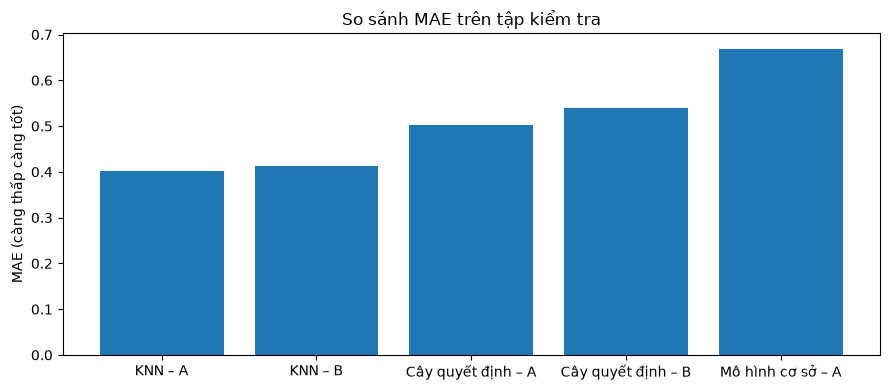

In [10]:
best_row = metrics.iloc[0]
best_key = f"{best_row['Mô hình']}_{best_row['Phương án']}"
best_pred = predictions[best_key]
print('Mô hình được chọn theo CV MAE:', best_key)
print('CV MAE:', round(float(best_row['CV MAE']), 4))
print('Test MAE:', round(float(best_row['Test MAE']), 4))
print('Test RMSE:', round(float(best_row['Test RMSE']), 4))
print('Test R²:', round(float(best_row['Test R²']), 4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(metrics['Mô hình'] + ' – ' + metrics['Phương án'], metrics['Test MAE'])
ax.set(title='So sánh MAE trên tập kiểm tra', ylabel='MAE (càng thấp càng tốt)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'so_sanh_sai_so_MAE.png', dpi=150); plt.show()

In [11]:
baseline = metrics.loc[metrics['Mô hình'] == 'Mô hình cơ sở'].iloc[0]
chenh = float(baseline['Test MAE'] - best_row['Test MAE'])
print('SO SÁNH VỚI MÔ HÌNH CƠ SỞ:')
print(f"DummyRegressor: Test MAE = {baseline['Test MAE']:.4f}; mô hình được chọn: {best_row['Test MAE']:.4f}.")
print(f"Chênh lệch MAE = {chenh:+.4f} điểm; giảm tương đối = {chenh / baseline['Test MAE'] * 100:+.1f}%.")
if chenh > 0: print('Nhận xét: Mô hình được chọn có sai số test thấp hơn mô hình dự đoán trung bình.')
elif chenh < 0: print('Nhận xét: Mô hình được chọn chưa vượt mô hình cơ sở trên test; cần thảo luận nguyên nhân.')
else: print('Nhận xét: Hai mô hình có MAE test bằng nhau.')

SO SÁNH VỚI MÔ HÌNH CƠ SỞ:
DummyRegressor: Test MAE = 0.6691; mô hình được chọn: 0.4019.
Chênh lệch MAE = +0.2672 điểm; giảm tương đối = +39.9%.
Nhận xét: Mô hình được chọn có sai số test thấp hơn mô hình dự đoán trung bình.


## Mission 7 – Phân tích sai số và trực quan hóa

Sai số có dấu được định nghĩa là **thực tế − dự đoán**: dương nghĩa là mô hình dự đoán thấp hơn thực tế; âm nghĩa là dự đoán cao hơn thực tế.

Biểu đồ phân phối sai số giúp nhận biết độ lệch; biểu đồ thực tế–dự đoán có đường chéo $y=x$ là dự đoán lý tưởng. Các điểm xa đường chéo thể hiện sai số lớn. Cần kiểm tra thêm sai số theo từng mức điểm `quality`, vì điểm ít gặp có thể khó dự đoán.

,Thực tế,Dự đoán,Sai số,Sai số tuyệt đối
871,3,6.015,-3.015,3.015
191,3,5.636,-2.636,2.636
1086,3,5.523,-2.523,2.523
680,3,5.411,-2.411,2.411
511,4,6.187,-2.187,2.187
655,4,6.184,-2.184,2.184
613,3,5.179,-2.179,2.179
682,4,6.165,-2.165,2.165
975,8,5.864,2.136,2.136
158,8,5.871,2.129,2.129


findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

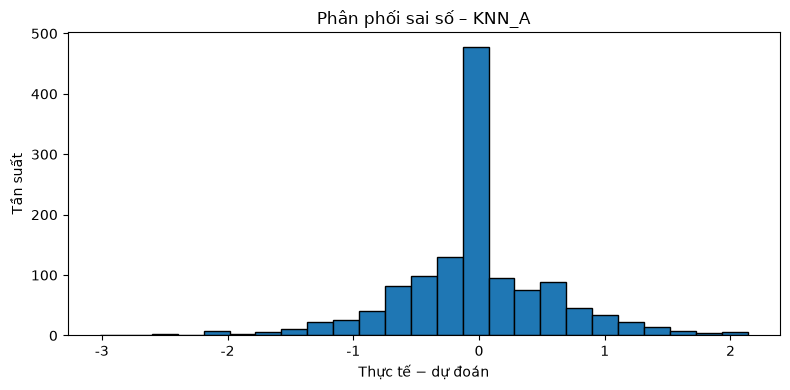

findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: Font family 'Noto Sans' not found.
findfont: 

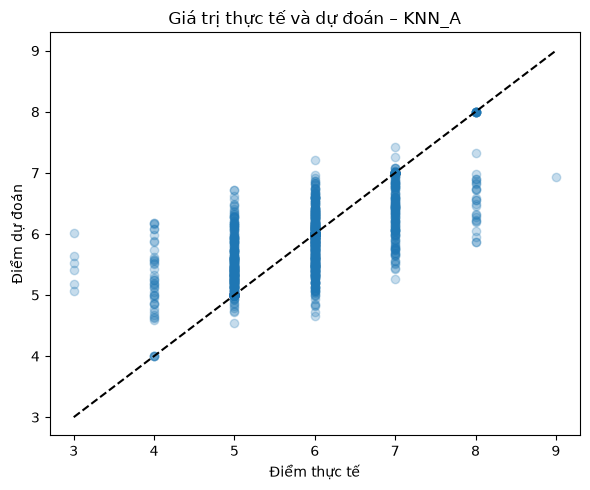

In [12]:
actual = np.asarray(y_test)
errors = actual - best_pred
error_table = pd.DataFrame({'Thực tế': actual, 'Dự đoán': best_pred,
                            'Sai số': errors, 'Sai số tuyệt đối': np.abs(errors)})
display(error_table.sort_values('Sai số tuyệt đối', ascending=False).head(10).round(3))
error_table.to_csv(OUT_DIR / 'bang_sai_so_du_doan.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(errors, bins=25, edgecolor='black')
ax.set(title=f'Phân phối sai số – {best_key}', xlabel='Thực tế − dự đoán', ylabel='Tần suất')
plt.tight_layout(); plt.savefig(OUT_DIR / 'phan_phoi_sai_so.png', dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(actual, best_pred, alpha=0.25)
lims = [min(actual.min(), best_pred.min()), max(actual.max(), best_pred.max())]
ax.plot(lims, lims, 'k--')
ax.set(title=f'Giá trị thực tế và dự đoán – {best_key}', xlabel='Điểm thực tế', ylabel='Điểm dự đoán')
plt.tight_layout(); plt.savefig(OUT_DIR / 'thuc_te_va_du_doan.png', dpi=150); plt.show()

In [13]:
print('PHÂN TÍCH SAI SỐ THEO MỨC ĐIỂM:')
by_quality = (error_table.groupby('Thực tế')['Sai số tuyệt đối']
              .agg(['count','mean']).rename(columns={'count':'Số mẫu','mean':'MAE theo mức điểm'}))
display(by_quality.round(4))
by_quality.to_csv(OUT_DIR / 'sai_so_theo_muc_diem.csv', encoding='utf-8-sig')
print(f"Sai số trung bình có dấu = {errors.mean():+.4f} điểm (dương: xu hướng dự đoán thấp).")
print(f"Tỷ lệ mẫu có sai số tuyệt đối > 1 điểm = {(np.abs(errors)>1).mean()*100:.2f}%.")
print('Lưu ý: các mức điểm ít mẫu có MAE biến động mạnh; không diễn giải như kết luận nhân quả.')

PHÂN TÍCH SAI SỐ THEO MỨC ĐIỂM:


,Số mẫu,MAE theo mức điểm
Thực tế,,
3,6,2.4719
4,43,1.1952
5,402,0.3868
6,597,0.2758
7,215,0.4502
8,36,1.0353
9,1,2.0668


Sai số trung bình có dấu = -0.0248 điểm (dương: xu hướng dự đoán thấp).
Tỷ lệ mẫu có sai số tuyệt đối > 1 điểm = 10.77%.
Lưu ý: các mức điểm ít mẫu có MAE biến động mạnh; không diễn giải như kết luận nhân quả.


## Mission 8 – Tổng kết và hạn chế

**Quy trình:** UCI Wine Quality → EDA → train/test → Pipeline A/B → 5-fold CV → chọn theo CV MAE → đánh giá test → phân tích sai số.

**Hạn chế:** dữ liệu điểm chất lượng không cân đối; chỉ thử KNN và cây quyết định; dữ liệu đỏ/trắng có thể có phân phối khác nhau; một lần chia train/test không cho thấy toàn bộ độ biến thiên kết quả. Chưa có kiểm định trên dữ liệu ngoài UCI.

**Hướng mở rộng:** đánh giá riêng đỏ/trắng, so sánh thêm Random Forest, lặp nhiều cách chia, phân tích sai số theo nhóm chất lượng và kiểm tra ổn định mô hình.

Phần kết luận bên dưới được sinh từ **số liệu thực tế của lần chạy**, không điền điểm số ước lượng.

In [14]:
print('TÓM TẮT THỰC NGHIỆM')
print('Tổng số mẫu:', len(df))
print('Mô hình tốt nhất theo kiểm định chéo:', best_key)
print('MAE kiểm định chéo:', round(float(best_row['CV MAE']), 4))
print('MAE tập kiểm tra:', round(float(best_row['Test MAE']), 4))
print('Kết quả và biểu đồ đã lưu tại:', OUT_DIR.resolve())

nhan_xet = [
    'BÁO CÁO KẾT QUẢ THỰC NGHIỆM – ĐỀ TÀI 15',
    f'Tổng số mẫu dữ liệu: {len(df)}',
    f'Số đặc trưng đầu vào: {X.shape[1]}',
    f'Số mẫu huấn luyện: {len(X_train)}; số mẫu kiểm tra: {len(X_test)}',
    f'Mô hình được chọn theo MAE kiểm định chéo: {best_key}',
    f'MAE kiểm định chéo: {best_row["CV MAE"]:.4f}',
    f'MAE tập kiểm tra: {best_row["Test MAE"]:.4f}',
    f'RMSE tập kiểm tra: {best_row["Test RMSE"]:.4f}',
    f'R² tập kiểm tra: {best_row["Test R²"]:.4f}',
    'Giải thích: MAE và RMSE càng thấp càng tốt; R² càng gần 1 thường càng tốt.',
    'Mô hình được chọn bằng kiểm định chéo trên tập huấn luyện, không chọn theo điểm tập kiểm tra.',
    'Các kết quả chỉ mô tả chất lượng dự đoán trên bộ dữ liệu được sử dụng.'
]
(OUT_DIR / 'bao_cao_ket_qua_tieng_viet.txt').write_text('\n'.join(nhan_xet), encoding='utf-8-sig')
print('Đã lưu báo cáo diễn giải bằng tiếng Việt: bao_cao_ket_qua_tieng_viet.txt')

TÓM TẮT THỰC NGHIỆM
Tổng số mẫu: 6497
Mô hình tốt nhất theo kiểm định chéo: KNN_A
MAE kiểm định chéo: 0.4256
MAE tập kiểm tra: 0.4019
Kết quả và biểu đồ đã lưu tại: E:\DeTai15_BanNangCap_BaoVe\DeTai15_BanBaoVe_Nhom4\results
Đã lưu báo cáo diễn giải bằng tiếng Việt: bao_cao_ket_qua_tieng_viet.txt


In [15]:
conclusion = [
    'KẾT LUẬN THỰC NGHIỆM – ĐỀ TÀI 15',
    f'Bộ dữ liệu: {len(df)} mẫu, {X.shape[1]} đặc trưng; train {len(X_train)}, test {len(X_test)}.',
    f'Mô hình chọn theo CV MAE: {best_key}.',
    f'CV MAE = {best_row["CV MAE"]:.4f}; Test MAE = {best_row["Test MAE"]:.4f}; RMSE = {best_row["Test RMSE"]:.4f}; R² = {best_row["Test R²"]:.4f}.',
    f'Mô hình cơ sở có Test MAE = {baseline["Test MAE"]:.4f}; mức giảm MAE = {chenh:.4f} điểm ({chenh/baseline["Test MAE"]*100:+.1f}%).',
    f'Sai số có dấu trung bình = {errors.mean():+.4f}; tỷ lệ sai số tuyệt đối >1 điểm = {(np.abs(errors)>1).mean()*100:.2f}%.',
    'Mô hình được chọn trên tập train bằng kiểm định chéo; các chỉ số test là đánh giá trên tập giữ lại.',
    'Giới hạn: dữ liệu không cân đối theo điểm chất lượng, một cách chia dữ liệu, chưa kiểm tra dữ liệu ngoài UCI.',
    'Hướng mở rộng: đánh giá riêng đỏ/trắng, thử thêm mô hình, kiểm định tính ổn định qua nhiều lần chia.'
]
print('\n'.join(conclusion))
(OUT_DIR / 'ket_luan_thuc_nghiem.txt').write_text('\n'.join(conclusion), encoding='utf-8-sig')

KẾT LUẬN THỰC NGHIỆM – ĐỀ TÀI 15
Bộ dữ liệu: 6497 mẫu, 12 đặc trưng; train 5197, test 1300.
Mô hình chọn theo CV MAE: KNN_A.
CV MAE = 0.4256; Test MAE = 0.4019; RMSE = 0.6112; R² = 0.4942.
Mô hình cơ sở có Test MAE = 0.6691; mức giảm MAE = 0.2672 điểm (+39.9%).
Sai số có dấu trung bình = -0.0248; tỷ lệ sai số tuyệt đối >1 điểm = 10.77%.
Mô hình được chọn trên tập train bằng kiểm định chéo; các chỉ số test là đánh giá trên tập giữ lại.
Giới hạn: dữ liệu không cân đối theo điểm chất lượng, một cách chia dữ liệu, chưa kiểm tra dữ liệu ngoài UCI.
Hướng mở rộng: đánh giá riêng đỏ/trắng, thử thêm mô hình, kiểm định tính ổn định qua nhiều lần chia.


649